# Computing for AI

Reference notebook. No exercises and no checks. Run the cells from the top.

- Timings change from run to run and from machine to machine. Prose states ratios and rules, not your timings. Read the printed output for your numbers.
- Tables marked "Recorded" were measured once on GMU's Hopper cluster (one NVIDIA A100, 80 GB, 22 October 2026). They are not recomputed here.
- Libraries: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`, `jax`.

| Section | Topic |
|---|---|
| 1. Cost and vectorization | Simulation cost, seeds, split search |
| 2. Parallel work | Forests, map-reduce |
| 3. Linear algebra cost and GPUs | FLOPs, solve against inverse, CPU against GPU |
| 4. Numbers on a computer | Overflow, logs, log-sum-exp, dtypes |
| 5. Automatic differentiation with JAX | Backpropagation, `grad`, `jit`, keys |
| 6. Training at scale | Minibatches, memory, data parallelism, energy |


In [1]:
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import time
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from jax import grad, jit, random
from sklearn.ensemble import RandomForestRegressor
from torch import nn

DATA = Path("data")
DATA.mkdir(exist_ok=True)
BASE = "https://vsokolov.org/courses/files/600/data"
for name in ("SaratogaHouses.csv", "circle.csv"):
    if not (DATA / name).exists():
        urlretrieve(f"{BASE}/{name}", DATA / name)

plt.rcParams["figure.figsize"] = (5, 3.5)
np.set_printoptions(precision=4, suppress=True)


def best_of(f, repeat=3):
    # run f a few times and return the fastest time in seconds
    times = []
    for _ in range(repeat):
        t0 = perf_counter()
        f()
        times.append(perf_counter() - t0)
    return min(times)


## 1. Cost and vectorization

Supports: simulation, multiple testing and tree models.

- Cost: the number of basic operations an algorithm needs, as a function of the size of the input.
- Vectorization: write a whole batch of work as one array operation, not a Python loop.
- Rule: loop only over steps that depend on the previous step. Everything else is an array.

### Two ways to process a vector

Observed vector $x = (x_1, \dots, x_n)$, $n = 10^6$. Task: $\sum_i x_i^2$.

- Loop: one element at a time in Python.
- Vectorized: one array operation.


In [2]:
rng_v = np.random.default_rng(11)
x = rng_v.standard_normal(1_000_000)

def sum_sq_loop(x):
    total = 0.0
    for xi in x:
        total += xi * xi
    return total

def sum_sq_vec(x):
    return np.sum(x * x)

t0 = time.perf_counter(); s_loop = sum_sq_loop(x); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); s_vec = sum_sq_vec(x); t_vec = time.perf_counter() - t0
print(f"loop      : {s_loop:.4f}  {t_loop * 1000:.1f} ms")
print(f"vectorized: {s_vec:.4f}  {t_vec * 1000:.1f} ms")
print(f"the loop is {t_loop / t_vec:.0f} times slower")


loop      : 999015.9548  74.5 ms
vectorized: 999015.9548  1.4 ms
the loop is 54 times slower


- Same answer (up to rounding in the last digits). The loop is about 54 times slower.

### Many variants

20 variants against one control, 1,000 visitors per arm, all with true rate 0.30. Count the variants that look significant in each experiment.


In [3]:
from scipy import stats

def many_variants(n_exp=1000, k=20, n=1000, rate=0.30, seed=12):
    rng = np.random.default_rng(seed)
    control = rng.binomial(n, rate, size=(n_exp, 1))
    variants = rng.binomial(n, rate, size=(n_exp, k))
    p_hat = (control + variants) / (2 * n)
    z = (variants - control) / n / np.sqrt(p_hat * (1 - p_hat) * 2 / n)
    return 2 * (1 - stats.norm.cdf(np.abs(z)))          # p-values, shape (n_exp, k)

pv = many_variants()
sig = (pv < 0.05).sum(axis=1)
print(f"average number of false winners per experiment: {sig.mean():.2f}")
print(f"share of experiments with at least one false winner: {(sig >= 1).mean():.3f}  (theory: {1 - 0.95**20:.3f})")
print(f"Bonferroni (cutoff 0.05/20 = {0.05 / 20}): share with at least one false winner: {(pv < 0.05 / 20).any(axis=1).mean():.3f}")


average number of false winners per experiment: 0.94
share of experiments with at least one false winner: 0.413  (theory: 0.642)
Bonferroni (cutoff 0.05/20 = 0.0025): share with at least one false winner: 0.025


- Average false winners per experiment: 0.94. Experiments with at least one: 0.413.
- Theory for 20 independent tests: $1 - 0.95^{20}$ = 0.642. The simulation gives less because the variants share one control.
- Bonferroni: divide the cutoff by the number of tests, $0.05/20 = 0.0025$. Chance of any false winner: 0.025.

### Seeds

- Seed: the starting state of a random number stream. The same seed gives the same numbers.
- Give each experiment its own seed. `SeedSequence(...).spawn(k)` makes `k` independent streams from one master seed.


In [4]:
print("same seed, run twice:", np.random.default_rng(1).random(3).round(3), np.random.default_rng(1).random(3).round(3))
print("different seed      :", np.random.default_rng(2).random(3).round(3))

streams = [np.random.default_rng(s) for s in np.random.SeedSequence(2026).spawn(3)]
print("three spawned streams, first draw each:", [round(g.random(), 3) for g in streams])
print("spawn again from the same master seed :", [round(np.random.default_rng(s).random(), 3) for s in np.random.SeedSequence(2026).spawn(3)])


same seed, run twice: [0.512 0.95  0.144] [0.512 0.95  0.144]
different seed      : [0.262 0.298 0.814]
three spawned streams, first draw each: [0.383, 0.671, 0.551]
spawn again from the same master seed : [0.383, 0.671, 0.551]


### Split search in a tree

- One feature: sort the $n$ rows by the feature, then slide the cut from left to right and update sums. Sort cost: about $n \log n$ steps. Slide cost: $n$.
- A tree repeats this for every feature at every node. With $p$ features, one level costs about $p \, n \log n$.
- Big trees on big tables are slow for this reason.

The cell times a sort for three values of $n$. When $n$ grows by 10, the time grows by about 10 to 15.


In [5]:
homes = pd.read_csv(DATA / "SaratogaHouses.csv", index_col=0)
Xall = pd.get_dummies(homes.drop(columns="price"), drop_first=True).astype(float)
yall = homes.price.to_numpy()
order = np.random.default_rng(10).permutation(len(homes))
n_train = int(0.7 * len(homes))
Xtr, ytr = Xall.iloc[order[:n_train]], yall[order[:n_train]]

rng_sort = np.random.default_rng(0)
sort_times = {}
for n_rows in (10**5, 10**6, 10**7):
    feature = rng_sort.standard_normal(n_rows)
    sort_times[n_rows] = best_of(lambda: np.sort(feature))
    print(f"sort {n_rows:>10,} numbers: {1000 * sort_times[n_rows]:8.1f} ms")
print(f"Saratoga has {Xall.shape[1]} features: one level of splits sorts about {Xall.shape[1]} columns of {len(Xtr)} rows.")


sort    100,000 numbers:      3.0 ms
sort  1,000,000 numbers:     35.4 ms


sort 10,000,000 numbers:    406.8 ms
Saratoga has 18 features: one level of splits sorts about 18 columns of 1209 rows.


## 2. Parallel work

Supports: random forests and boosting; experiments with counts that add up (Beta posteriors).

- Parallel work: pieces that do not need each other can run on different processors at the same time.
- Speed-up: time on one core divided by time on all cores. It stays below the number of cores, because starting workers and collecting results costs time.

### Forests run in parallel, boosting does not

- Forest: each tree is grown on its own bootstrap sample. No tree needs another tree. `n_jobs=-1` means use all cores.
- Boosting: tree $k$ is fitted to the mistakes left by trees 1 to $k-1$. It must wait for them. Scikit-learn's boosting has no `n_jobs`.
- Other libraries may parallelize the work inside one tree.

Same forest, 300 trees, on one core and on all cores.


In [6]:
def fit_forest(jobs):
    RandomForestRegressor(n_estimators=300, max_features=1 / 3, random_state=0, n_jobs=jobs).fit(Xtr, ytr)

time_1 = best_of(lambda: fit_forest(1), repeat=2)
time_all = best_of(lambda: fit_forest(-1), repeat=2)
n_cores = os.cpu_count()
print(f"this computer reports {n_cores} cores")
print(f"300 trees on 1 core:  {time_1:.2f} s")
print(f"300 trees on all cores: {time_all:.2f} s")
print(f"speed-up: {time_1 / time_all:.1f}x")


this computer reports 8 cores
300 trees on 1 core:  0.44 s
300 trees on all cores: 0.16 s
speed-up: 2.7x


### Map-reduce on sufficient statistics

- Sufficient statistic: a small summary that holds everything the data say about the parameter. For a purchase rate it is (buys, visitors).
- Map: each server computes the statistic on its own piece of the data.
- Reduce: add the statistics.
- Beta update: prior Beta($a$, $b$), $s$ buys in $n$ visitors, posterior Beta($a + s$, $b + n - s$). It only adds counts, so the order and the grouping do not matter.

The log of 500 visitors (200 buys) is split over 4 "servers".


In [7]:
a0, b0 = 1, 1                                                            # flat Beta(1, 1) prior
n_pink, buys_pink = 500, 200
rng_s = np.random.default_rng(4)
pink_log = np.r_[np.ones(buys_pink), np.zeros(n_pink - buys_pink)]      # 200 buys, 300 non-buys
rng_s.shuffle(pink_log)
servers = np.array_split(pink_log, 4)

mapped = [(int(s.sum()), len(s)) for s in servers]                       # map: (buys, visitors) per server
print("per-server (buys, visitors):", mapped)
buys_total = sum(m[0] for m in mapped)                                   # reduce: add the counts
n_total = sum(m[1] for m in mapped)
print("reduced posterior : Beta", (a0 + buys_total, b0 + n_total - buys_total))
print("full-log posterior: Beta", (a0 + int(pink_log.sum()), b0 + len(pink_log) - int(pink_log.sum())))


per-server (buys, visitors): [(54, 125), (44, 125), (51, 125), (51, 125)]
reduced posterior : Beta (201, 301)
full-log posterior: Beta (201, 301)


- Each server sends two numbers, not its whole log.
- The reduced posterior, Beta(201, 301), equals the posterior from the full log.
- Data parallel training uses the same pattern: each GPU computes a gradient on its shard, and the gradients are averaged (Section 6).


## 3. Linear algebra cost and GPUs

Supports: regression and ridge in matrix form; the forward pass of a network.

### What a matrix product costs

- FLOP: one floating-point operation (one addition or one multiplication).
- Matrix product cost: $2ndm$ FLOPs for an $(n \times d)$ matrix times a $(d \times m)$ matrix. Each of the $n \times m$ outputs needs $d$ multiplications and $d$ additions.
- A forward pass for a batch is one such product per layer.
- Speed: FLOPs divided by seconds. GFLOP/s is $10^9$ FLOP per second, TFLOP/s is $10^{12}$.

Triple Python loop against one `X @ W`, for $n = 1000$, $d = 20$, $m = 32$.


In [8]:
rng_mm = np.random.default_rng(2)
n_mm, d_mm, m_mm = 1000, 20, 32
Xm = rng_mm.standard_normal((n_mm, d_mm))
Wm = rng_mm.standard_normal((d_mm, m_mm))

def triple_loop(X, W):
    out = np.zeros((X.shape[0], W.shape[1]))
    for i in range(X.shape[0]):
        for j in range(W.shape[1]):
            for k in range(X.shape[1]):
                out[i, j] += X[i, k] * W[k, j]
    return out

loop_result = triple_loop(Xm, Wm)
time_loop = best_of(lambda: triple_loop(Xm, Wm), repeat=1)
time_vec = best_of(lambda: Xm @ Wm, repeat=20)
flops_mm = 2 * n_mm * d_mm * m_mm
print("same answer:", np.allclose(loop_result, Xm @ Wm))
print(f"FLOPs: 2 * {n_mm} * {d_mm} * {m_mm} = {flops_mm:,}")
print(f"triple loop: {time_loop:.3f} s   X @ W: {1000 * time_vec:.3f} ms   ratio {time_loop / time_vec:,.0f}x")
print(f"X @ W runs at about {flops_mm / time_vec / 1e9:.1f} GFLOP/s")


same answer: True
FLOPs: 2 * 1000 * 20 * 32 = 1,280,000
triple loop: 0.145 s   X @ W: 0.009 ms   ratio 15,905x
X @ W runs at about 140.3 GFLOP/s


- The product needs 1,280,000 FLOPs.
- The loop is far slower than `X @ W`. The gap comes from compiled, cache-friendly code that uses vector instructions and several cores.
- Rule: write the whole batch as one array operation.

### Solve, do not invert

- Ridge normal equations: $(X^\top X + \lambda I)\,\beta = X^\top y$. Symbols: $X$ the $n \times p$ design matrix, $y$ the outcome, $\lambda$ the penalty, $I$ the identity, $\beta$ the coefficients.
- Textbook formula: $\beta = (X^\top X + \lambda I)^{-1} X^\top y$. In code, `np.linalg.inv(A) @ b` builds the inverse. `np.linalg.solve(A, b)` solves the system directly.
- Condition number: how much a matrix magnifies small errors. A condition number of $10^{k}$ loses about $k$ of the 16 digits of a `float64`.
- Setup: 2000 rows, 50 features, feature 2 equals feature 1 plus noise of size $10^{-6}$ (nearly collinear).


In [9]:
rng_c = np.random.default_rng(0)
Xn = rng_c.standard_normal((2000, 50))
Xn[:, 1] = Xn[:, 0] + 1e-6 * rng_c.standard_normal(2000)       # nearly collinear
beta_star = np.zeros(50); beta_star[2:7] = 1.0                 # the truth does not use features 0 and 1
yn = Xn @ beta_star + 0.1 * rng_c.standard_normal(2000)

G, rhs = Xn.T @ Xn, Xn.T @ yn
rows = []
for lam_c in (0.0, 1.0):
    A = G + lam_c * np.eye(50)
    t0 = time.perf_counter(); b_inv = np.linalg.inv(A) @ rhs; t_inv = time.perf_counter() - t0
    t0 = time.perf_counter(); b_sol = np.linalg.solve(A, rhs); t_sol = time.perf_counter() - t0
    rows.append((lam_c, np.linalg.cond(A),
                 np.linalg.norm(A @ b_inv - rhs), np.linalg.norm(A @ b_sol - rhs),
                 np.linalg.norm(b_inv - beta_star), np.linalg.norm(b_sol - beta_star), t_inv, t_sol))
solve_tbl = pd.DataFrame(rows, columns=["lambda", "cond number", "residual inv", "residual solve",
                                        "coef error inv", "coef error solve", "time inv (s)", "time solve (s)"]).set_index("lambda")
pd.set_option("display.float_format", lambda v: f"{v:.3g}")
print(solve_tbl.T)
pd.reset_option("display.float_format")


lambda                  0        1
cond number      3.98e+12 3.95e+03
residual inv       0.0296 4.55e-11
residual solve   1.37e-09 2.06e-12
coef error inv   2.09e+03   0.0132
coef error solve 2.09e+03   0.0132
time inv (s)      0.00183  3.8e-05
time solve (s)     0.0002 2.22e-05


- Residual: $\|A\beta - X^\top y\|$, how badly the answer fails the equation.
- $\lambda = 0$: condition number 4.0e+12. Residual 3.0e-02 for `inv`, 1.4e-09 for `solve`.
- $\lambda = 1$: condition number 3.9e+03. Adding $\lambda I$ lifts the tiny eigenvalues of $X^\top X$ away from zero. A second job of the ridge penalty: it makes the problem solvable.
- Coefficient error against the true $\beta$ at $\lambda = 0$: 2.1e+03 (inv) and 2.1e+03 (solve). Both fail, because two features carry the same information. No solver can fix that.
- Coefficient error at $\lambda = 1$: 0.01 (inv) and 0.01 (solve). The penalty ties the two coefficients together.
- `solve` is faster (see the time rows) and never builds the full inverse.
- Rule: never write `inv(A) @ b`. Use `solve(A, b)`.

### CPU against GPU

- A GPU has thousands of small cores. It is fast at big matrix products and slow at small jobs.
- Device: `cuda` (Nvidia GPU), else `mps` (Apple silicon GPU), else `cpu`. With no GPU, the second column is PyTorch on the CPU.
- GPU calls return before the work is done. Call `synchronize()` before stopping the clock, or only the launch is timed.
- Each doubling of $n$ multiplies the work by 8 ($2n^3$ FLOPs).


device used by PyTorch: mps
     n    CPU (NumPy)     PyTorch on mps   CPU / device
   256        0.03 ms            0.26 ms          0.11x
  1024        1.93 ms            2.52 ms          0.77x
  2048       15.50 ms            7.01 ms          2.21x
  4096      124.03 ms           46.40 ms          2.67x


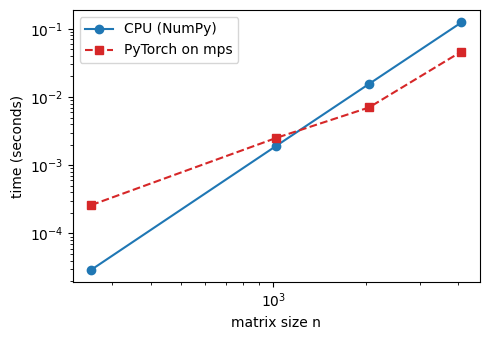

In [10]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

def sync():
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()

def time_numpy(n):
    a = np.random.default_rng(0).standard_normal((n, n)).astype(np.float32)
    b = np.random.default_rng(1).standard_normal((n, n)).astype(np.float32)
    a @ b
    return best_of(lambda: a @ b, repeat=3)

def time_torch(n):
    a = torch.randn(n, n, device=device, dtype=torch.float32)
    b = torch.randn(n, n, device=device, dtype=torch.float32)
    a @ b
    sync()
    def run():
        a @ b
        sync()
    return best_of(run, repeat=3)

sizes = [256, 1024, 2048, 4096]
cpu_times = [time_numpy(n) for n in sizes]
dev_times = [time_torch(n) for n in sizes]
print("device used by PyTorch:", device)
print(f"{'n':>6} {'CPU (NumPy)':>14} {'PyTorch on ' + device:>18} {'CPU / device':>14}")
for n, tc, tg in zip(sizes, cpu_times, dev_times):
    print(f"{n:>6} {1000 * tc:>11.2f} ms {1000 * tg:>15.2f} ms {tc / tg:>13.2f}x")

plt.loglog(sizes, cpu_times, "C0-o", label="CPU (NumPy)")
plt.loglog(sizes, dev_times, "C3--s", label=f"PyTorch on {device}")
plt.xlabel("matrix size n")
plt.ylabel("time (seconds)")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:
# Launch overhead and copy cost
x_small_np = np.ones(10, dtype=np.float32)
x_small = torch.ones(10, device=device)

def tiny_cpu():
    x = x_small_np
    for _ in range(1000):
        x = x + 1

def tiny_dev():
    x = x_small
    for _ in range(1000):
        x = x + 1
    sync()

tiny_cpu_time = best_of(tiny_cpu)
tiny_dev_time = best_of(tiny_dev)
print(f"1,000 tiny operations: NumPy {1000 * tiny_cpu_time:.2f} ms, PyTorch on {device} {1000 * tiny_dev_time:.2f} ms")

big = torch.empty(64 * 1024 * 1024, dtype=torch.float32)     # 256 MB on the CPU
t0 = perf_counter()
big_on_device = big.to(device)
sync()
copy_time = perf_counter() - t0
print(f"copying {big.numel() * 4 / 2**20:.0f} MB to {device}: {copy_time:.3f} s" + ("  (no copy needed: already on the CPU)" if device == "cpu" else ""))
del big_on_device


1,000 tiny operations: NumPy 0.51 ms, PyTorch on mps 4.94 ms
copying 256 MB to mps: 0.057 s


- Small jobs lose on a GPU: every call has a fixed launch cost.
- Moving data costs time. Keep data on the device and copy as rarely as possible.
- A laptop GPU wins by a small factor. Big gaps appear with data-center GPUs.

**Recorded on a data-center GPU.** One NVIDIA A100 (80 GB) on GMU's Hopper cluster, 22 October 2026, against 16 CPU cores of the same server. Time for one $n \times n$ matrix product. TF32 and bfloat16 are lower-precision number formats (Section 4) that the GPU computes faster. TF32 keeps the range of float32 with fewer digits.

| n | CPU, 16 cores, float32 | A100, float32 | A100, TF32 | A100, bfloat16 |
|---|---|---|---|---|
| 256 | 0.52 ms | 0.014 ms | 0.016 ms | 0.011 ms |
| 1,024 | 2.06 ms | 0.13 ms | 0.033 ms | 0.020 ms |
| 2,048 | 13 ms | 0.98 ms | 0.17 ms | 0.11 ms |
| 4,096 | 94 ms | 7.26 ms | 1.05 ms | 0.52 ms |
| 8,192 | 716 ms | 58 ms | 7.87 ms | 3.81 ms |

- Best speed measured: CPU 1.5 TFLOP/s. A100: 19 TFLOP/s in float32, 140 in TF32, 291 in bfloat16.
- At $n = 8{,}192$ the A100 is 12 times faster than the server CPU in float32 and 188 times faster in bfloat16. This GPU already wins at $n = 256$.
- 1,000 tiny operations: 6.5 ms on the GPU, 3.2 ms on the CPU.
- Copying 256 MB to the GPU: 19 ms (13 GB/s), about 5 times one $8{,}192$ bfloat16 product.


## 4. Numbers on a computer

Supports: log-likelihood and the Kelly bettor; softmax and cross-entropy.

- Floating point number: a stored value with a fixed number of bytes, hence a largest value, a smallest value, and a spacing between neighbours.
- Machine epsilon $\varepsilon$: the smallest relative step the computer sees, the spacing between 1 and the next number.
- Overflow: a result too large to store becomes `inf`. Underflow: a result too small becomes `0.0`.

### Why we add logs

A bankroll after 1,000 bets is a product of 1,000 numbers. The cell prints the limits of `float64`, then multiplies 1,000 threes and 1,000 times 0.3.


In [12]:
info = np.finfo(np.float64)
print('largest float64 :', info.max)
print('smallest normal float64:', info.tiny)
print('eps (smallest relative step):', info.eps)
print()
with np.errstate(over='ignore'):
    print('product of 1,000 threes   :', np.prod(np.full(1000, 3.0)))
    print('product of 1,000 times 0.3:', np.prod(np.full(1000, 0.3)))
    print('np.exp(1000)              :', np.exp(1000))
print('sum of logs of the threes :', round(np.sum(np.log(np.full(1000, 3.0))), 1))
print('so the product is 10 to the', round(np.sum(np.log10(np.full(1000, 3.0))), 1))
print()
print('np.log(1 + 1e-20) =', np.log(1 + 1e-20))
print('np.log1p(1e-20)   =', np.log1p(1e-20))


largest float64 : 1.7976931348623157e+308
smallest normal float64: 2.2250738585072014e-308
eps (smallest relative step): 2.220446049250313e-16

product of 1,000 threes   : inf
product of 1,000 times 0.3: 0.0
np.exp(1000)              : inf
sum of logs of the threes : 1098.6
so the product is 10 to the 477.1

np.log(1 + 1e-20) = 0.0
np.log1p(1e-20)   = 1e-20


- Largest `float64`: about 1.8e+308. The product of 1,000 threes is $3^{1000}$, about $10^{477}$. Too big: `inf`.
- The product of 1,000 times 0.3 is too small: `0.0`. `np.exp(1000)` is `inf` for the same reason.
- The sum of logs is a normal number: 1098.6.
- $\varepsilon$ = 2.2e-16. Adding $10^{-20}$ to 1 is below that step, so the sum stays 1 and `np.log(1 + 1e-20)` is 0.
- `np.log1p(x)` computes $\log(1+x)$ without that rounding.
- Rule: keep the log of any number that can be huge or tiny (a bankroll, a likelihood, the probability of a long sequence). Exponentiate only at the end, if at all.

### Where $2^k$ stops

The St. Petersburg payout is $2^T$ dollars for the first head on toss $T$. The payout is a float.


In [13]:
for k in (10, 100, 1023, 1024):
    with np.errstate(over='ignore'):
        print(f'2.0 ** {k:<5} =', np.float64(2.0) ** k)
print('np.exp(709) =', np.exp(709))
with np.errstate(over='ignore'):
    print('np.exp(710) =', np.exp(710))
print('Python integers do not overflow: 2 ** 1024 has', len(str(2 ** 1024)), 'digits')


2.0 ** 10    = 1024.0
2.0 ** 100   = 1.2676506002282294e+30
2.0 ** 1023  = 8.98846567431158e+307
2.0 ** 1024  = inf
np.exp(709) = 8.218407461554972e+307
np.exp(710) = inf
Python integers do not overflow: 2 ** 1024 has 309 digits


- `2.0 ** 1023` has 308 digits. `2.0 ** 1024` is `inf`.
- In `np.exp` the limit is 709.
- A Python integer has no limit, but it cannot be mixed with floats at large values.

### Softmax and log-sum-exp

- Softmax: $p_k = \dfrac{e^{s_k}}{\sum_j e^{s_j}}$. Symbols: $s = (s_1, \dots, s_K)$ the scores, $p_k$ the probability of class $k$.
- Cross-entropy loss for true class $c$: $L = -\log p_c = -s_c + \log \sum_k e^{s_k}$.
- Log-sum-exp: $\log\sum_k e^{s_k} = s_{\max} + \log\sum_k e^{s_k - s_{\max}}$, where $s_{\max} = \max_k s_k$.
- Softmax does not change if the same number is subtracted from every score. Subtracting $s_{\max}$ makes the largest exponent $e^0 = 1$.
- In `float64`, $e^{710}$ is already `inf`.


In [14]:
def log_softmax(z):
    # log p_k = z_k - log(sum_j exp(z_j)), with the max subtracted
    m = z.max(axis=-1, keepdims=True)
    return z - m - np.log(np.exp(z - m).sum(axis=-1, keepdims=True))

def softmax(z):
    return np.exp(log_softmax(z))

def cross_entropy(Z, idx):
    # average over the rows of Z of -log p of the true class, computed from the scores
    Z = np.atleast_2d(Z)
    return float(np.mean(-log_softmax(Z)[np.arange(len(Z)), idx]))

z3 = np.array([2.0, 1.0, 0.1])
p3 = softmax(z3)
print("probabilities:", p3.round(3), " sum:", p3.sum().round(3))
print("loss, true class 0:", round(cross_entropy(z3, [0]), 3), "  = -log p of the true class:", round(-np.log(p3[0]), 3))

s_big = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(all="ignore"):
    naive = np.exp(s_big) / np.exp(s_big).sum()
print("naive softmax of (1000, 1001, 1002):", naive)
print("stable softmax                     :", softmax(s_big))
print("stable softmax of (0, 1, 2)        :", softmax(np.array([0.0, 1.0, 2.0])))

z_big = np.array([0.0, 1000.0])                  # the true class is the first one
p_first = np.exp(z_big - z_big.max())[0] / np.exp(z_big - z_big.max()).sum()
with np.errstate(divide="ignore"):
    naive_loss = -np.log(p_first)
print("scores (0, 1000), true class 0: log(softmax) gives", naive_loss, "  log-sum-exp gives", cross_entropy(z_big, [0]))


probabilities: [0.659 0.242 0.099]  sum: 1.0
loss, true class 0: 0.417   = -log p of the true class: 0.417
naive softmax of (1000, 1001, 1002): [nan nan nan]
stable softmax                     : [0.09   0.2447 0.6652]
stable softmax of (0, 1, 2)        : [0.09   0.2447 0.6652]
scores (0, 1000), true class 0: log(softmax) gives inf   log-sum-exp gives 1000.0


- For scores (2.0, 1.0, 0.1) the probabilities are 0.659, 0.242, 0.099, and the loss for class 0 is 0.417.
- Naive softmax of (1000, 1001, 1002) gives `nan` (`inf` divided by `inf`). The stable one gives 0.0900, 0.2447, 0.6652, the same as for (0, 1, 2). Only the gaps between scores matter.
- With scores (0, 1000) the first probability rounds to exactly 0, so the log of the softmax is infinite. Log-sum-exp gives the correct loss, 1000.
- Rule: compute cross-entropy from the scores, not from `log(softmax(...))`.
- Libraries want raw scores. `nn.CrossEntropyLoss` (K classes) and `nn.BCEWithLogitsLoss` (two classes) apply the stable softmax or sigmoid inside. Never put a softmax or a sigmoid before them.
- Axes: for scores of shape (batch, classes), softmax and log-sum-exp go along the class axis (`axis=1`). Wrong axes still run and give the right shape. Check that each row sums to 1.


In [15]:
S_b = np.array([[2.0, 0.0, -1.0], [0.5, 0.5, 0.5], [0.0, 3.0, 1.0], [-1.0, 0.0, 2.0]])
lab_b = np.array([0, 2, 1, 2])
P_ok = softmax(S_b)
E = np.exp(S_b)
P_bad = E / E.sum(axis=0, keepdims=True)         # wrong axis: normalizes down the batch
print("axis=1 row sums:", P_ok.sum(axis=1))
print("axis=0 row sums:", P_bad.sum(axis=1), " column sums:", P_bad.sum(axis=0))

S_t = torch.tensor(S_b); lab_t = torch.tensor(lab_b)
loss_raw = nn.CrossEntropyLoss()(S_t, lab_t).item()
loss_twice = nn.CrossEntropyLoss()(torch.softmax(S_t, dim=1), lab_t).item()
print(f"CrossEntropyLoss on raw scores   : {loss_raw:.4f}")
print(f"CrossEntropyLoss after a softmax : {loss_twice:.4f}   (wrong: softmax applied twice)")


axis=1 row sums: [1. 1. 1. 1.]
axis=0 row sums: [0.7826 0.3639 1.1666 0.6869]  column sums: [1. 1. 1.]
CrossEntropyLoss on raw scores   : 0.4020
CrossEntropyLoss after a softmax : 0.7680   (wrong: softmax applied twice)


- Right axis: rows sum to 1. Wrong axis: columns sum to 1 and rows do not.
- Loss on raw scores: 0.4020. After your own softmax the loss applies another one inside: 0.7680. It runs and it is wrong.

### dtypes

- dtype: the number format of a tensor. Fewer bits mean less memory and faster math, but a smaller range and fewer digits.
- `float64`: NumPy's default, 8 bytes.
- `float32`: PyTorch's and JAX's default, 4 bytes.
- `float16`: 2 bytes, used on GPUs. Largest value 65,504.
- `bfloat16`: 2 bytes. Same range as float32, about 2 to 3 digits.
- NumPy arrays default to `float64`, PyTorch tensors to `float32`. A common source of dtype errors.


In [16]:
for dt in (torch.float64, torch.float32, torch.float16, torch.bfloat16):
    fi = torch.finfo(dt)
    print(f"{str(dt):15s} bytes {fi.bits // 8}   largest {fi.max:.3g}   spacing near 1: {fi.eps:.1e}")

s16 = np.array([12.0, 11.0, 10.0], dtype=np.float16)
with np.errstate(all="ignore"):
    naive16 = np.exp(s16) / np.exp(s16).sum()
stable16 = softmax(s16)
print("float16 naive softmax of (12, 11, 10):", naive16)
print("float16 stable softmax               :", stable16, stable16.dtype)

t = torch.ones(3, 2, dtype=torch.float64)
t32 = torch.ones(3, 2)                       # float32 by default
try:
    torch.ones(2, 3, dtype=torch.float64) @ t32
except RuntimeError as e:
    print("float64 @ float32 stops with:", str(e)[:70])
print("after .to(float32):", (torch.ones(2, 3, dtype=torch.float64).to(torch.float32) @ t32).tolist())


torch.float64   bytes 8   largest 1.8e+308   spacing near 1: 2.2e-16
torch.float32   bytes 4   largest 3.4e+38   spacing near 1: 1.2e-07
torch.float16   bytes 2   largest 6.55e+04   spacing near 1: 9.8e-04
torch.bfloat16  bytes 2   largest 3.39e+38   spacing near 1: 7.8e-03
float16 naive softmax of (12, 11, 10): [nan  0.  0.]
float16 stable softmax               : [0.6655 0.2449 0.09  ] float16
float64 @ float32 stops with: expected m1 and m2 to have the same dtype, but got: double != float
after .to(float32): [[3.0, 3.0], [3.0, 3.0]]


- float16 largest number: 65,504. $e^{12}$ = 162,755 is bigger, so `np.exp(12)` is `inf` and the naive softmax is `nan`.
- After the max subtraction the result is fine: 0.666, 0.245, 0.090.
- bfloat16 has the range of float32, so it does not overflow here. Its spacing near 1 is 7.8e-03, about 8 times coarser than float16 (9.8e-04).


## 5. Automatic differentiation with JAX

Supports: backpropagation and training a network.

- Automatic differentiation (AD): the computer applies the chain rule to the program, node by node. No derivative formula is written by hand.
- Forward mode: carries derivatives with the computation. Cheap when there are few inputs and many outputs.
- Reverse mode: carries derivatives against the computation, from the output back. Cheap when there are many inputs and one output.
- A network has millions of inputs (weights) and one output (the loss), so it uses reverse mode.
- Backpropagation: reverse-mode automatic differentiation.

### Reverse mode by hand

Example: $f = \sigma(wx + b)$ with $\sigma(v) = 1/(1+e^{-v})$. Symbols: $x$ input, $w$ weight, $b$ bias. Take $x = 2$, $w = 3$, $b = -5$.

- Graph: $v_1 = wx$, $v_2 = v_1 + b$, $f = \sigma(v_2)$.
- Start at the output with $df/df = 1$. At each node multiply by the local derivative.
- $df/dv_2 = f(1-f)$, $df/dv_1 = df/dv_2$, $df/db = df/dv_2$, $df/dx = (df/dv_1)\, w$, $df/dw = (df/dv_1)\, x$.
- One backward pass gives the derivative with respect to every input.


In [17]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

xv, wv, bv = 2.0, 3.0, -5.0
v1 = wv * xv
v2 = v1 + bv
v3 = sigmoid(v2)

df_dv3 = 1.0
df_dv2 = df_dv3 * v3 * (1 - v3)
df_dv1 = df_dv2 * 1.0
rev_db = df_dv2 * 1.0
rev_dx = df_dv1 * wv
rev_dw = df_dv1 * xv
print(f"f = {v3:.3f}")
print(f"reverse mode: df/dx = {rev_dx:.3f}, df/dw = {rev_dw:.3f}, df/db = {rev_db:.3f}")

# Finite differences, for comparison (float64).
fd_errs = {}
for h in (1e-1, 1e-3, 1e-6, 1e-10, 1e-14):
    approx = (sigmoid((wv + h) * xv + bv) - sigmoid(wv * xv + bv)) / h
    fd_errs[h] = abs(approx - rev_dw)
    print(f"h = {h:.0e}: finite difference for df/dw = {approx:.8f}, error = {fd_errs[h]:.1e}")


f = 0.731
reverse mode: df/dx = 0.590, df/dw = 0.393, df/db = 0.197
h = 1e-01: finite difference for df/dw = 0.37466205, error = 1.9e-02
h = 1e-03: finite difference for df/dw = 0.39304210, error = 1.8e-04
h = 1e-06: finite difference for df/dw = 0.39322368, error = 1.8e-07
h = 1e-10: finite difference for df/dw = 0.39322323, error = 6.3e-07
h = 1e-14: finite difference for df/dw = 0.39968029, error = 6.5e-03


- Finite difference: $\big(f(w+h) - f(w)\big)/h$ for a small step $h$.
- Step $h = 0.1$: error 1.9e-02, the step is too big.
- Step $h = 10^{-14}$: error 6.5e-03, rounding error dominates.
- Reverse mode has no step size and no such trade-off.

### JAX: `grad`, `argnums`, `jit`

- `jax.grad(f)`: a new function that computes the derivative of `f` with respect to its first argument.
- `argnums=(0, 1, 2)`: derivatives with respect to several arguments at once.
- `jax.jit`: compiles a function, so it runs faster after the first call.
- JAX works in float32 by default, so numbers agree with float64 to about 7 digits.


In [18]:
def f_jax(x, w, b):
    return 1 / (1 + jnp.exp(-(w * x + b)))

print("f      =", float(f_jax(xv, wv, bv)))
print("df/dx  =", float(grad(f_jax)(xv, wv, bv)))
dx, dw, db = grad(f_jax, argnums=(0, 1, 2))(xv, wv, bv)
print(f"all three at once: df/dx = {float(dx):.3f}, df/dw = {float(dw):.3f}, df/db = {float(db):.3f}")
fast = jit(grad(f_jax, argnums=(0, 1, 2)))
print("jit version:", [round(float(a), 3) for a in fast(xv, wv, bv)])


f      = 0.7310585975646973
df/dx  = 0.5898358821868896
all three at once: df/dx = 0.590, df/dw = 0.393, df/db = 0.197
jit version: [0.59, 0.393, 0.197]


- `grad` gives 0.590, 0.393, 0.197, the same as the hand calculation, from one call.

### The gradient of softmax cross-entropy

- Loss for true class $c$: $L = -s_c + \log\sum_k e^{s_k}$.
- Derivative with respect to score $s_j$: $\dfrac{\partial L}{\partial s_j} = p_j - y_j$. Symbols: $p_j$ the softmax probability, $y_j$ the one-hot label (1 for the true class, 0 otherwise).
- For a batch of $n$ examples and the mean loss, the gradient with respect to the score matrix is $(P - Y)/n$, where $P$ and $Y$ have one row per example.
- This is where backpropagation starts for every classifier.

Check three ways: the formula, a finite difference, and `jax.grad`. Scores (2, 1, 0.1), true class 1.


In [19]:
def logsumexp(S, axis=-1):
    m = S.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(S - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def ce_one(s, c):
    return logsumexp(s) - s[c]            # = -log p_c

s_ex = np.array([2.0, 1.0, 0.1]); c_ex = 1
y_onehot = np.eye(3)[c_ex]
formula = softmax(s_ex) - y_onehot
h = 1e-6
fin_diff = np.array([(ce_one(s_ex + h * np.eye(3)[j], c_ex) - ce_one(s_ex - h * np.eye(3)[j], c_ex)) / (2 * h)
                     for j in range(3)])
by_grad = np.array(grad(lambda s: jax.nn.logsumexp(s) - s[c_ex])(jnp.array(s_ex)))
np.set_printoptions(precision=7)
print("scores              :", s_ex, " true class:", c_ex)
print("probabilities p     :", softmax(s_ex))
print("formula p - y       :", formula)
print("finite difference   :", fin_diff)
print("jax.grad            :", by_grad)
np.set_printoptions(precision=4)


scores              : [2.  1.  0.1]  true class: 1
probabilities p     : [0.6590011 0.242433  0.0985659]
formula p - y       : [ 0.6590011 -0.757567   0.0985659]
finite difference   : [ 0.6590011 -0.757567   0.0985659]
jax.grad            : [ 0.6590012 -0.757567   0.0985659]


- The three methods agree to about 6 digits. The float32 `jax.grad` differs from the formula only in the 7th digit.
- Signs: the true class has a negative entry (its score should go up). The others are positive (their scores should go down).

### Random keys

- JAX has no hidden random state. Every random draw takes an explicit key.
- The same key gives the same numbers. Reusing one key for several arrays gives arrays that are scaled copies of each other.
- `random.split(key, k)` makes `k` independent keys.

Network 2-4-1 on the circle data: two inputs, four sigmoid hidden units, one sigmoid output. Loss: negative log-likelihood summed over 200 points. Plain gradient descent, 1,500 steps, learning rate 0.02. `grad` gives the gradient of all four weight arrays, and `jit` compiles the step.


In [20]:
circle = pd.read_csv(DATA / "circle.csv")
xc = circle[["x1", "x2"]].to_numpy()
yc = circle["label"].to_numpy().astype(float)
print("data:", xc.shape, yc.shape, "share of ones:", yc.mean())

k = random.PRNGKey(0)                       # one key for all four arrays
w1 = 0.1 * random.normal(k, (2, 4))
b1 = 0.01 * random.normal(k, (4,))
w2 = 0.1 * random.normal(k, (4, 1))
b2 = 0.01 * random.normal(k, (1,))
print("b1 / 0.01      :", np.array(b1 / 0.01))
print("w1[0, :] / 0.1:  ", np.array(w1.ravel()[:4] / 0.1))
print("w2 / 0.1       :", np.array(w2.ravel() / 0.1))
print("b2 / 0.01      :", np.array(b2 / 0.01))
same_key = np.array(b1 / 0.01)


data: (200, 2) (200,) share of ones: 0.5


b1 / 0.01      : [ 1.6226  2.0253 -0.4336 -0.0786]
w1[0, :] / 0.1:   [ 1.6226  2.0253 -0.4336 -0.0786]
w2 / 0.1       : [ 1.6226  2.0253 -0.4336 -0.0786]
b2 / 0.01      : [1.6226]


- One key used four times: the same four numbers (1.6226, 2.0253, ...) appear in `b1`, in the first row of `w1`, and in `w2`. Only the scale differs.
- The arrays are not independent. The network still trains, but the starting weights are not what they appear to be.


In [21]:
def logit(x, w1, b1, w2, b2):
    z = 1 / (1 + jnp.exp(-(jnp.dot(x, w1) + b1)))      # sigmoid hidden units
    return (jnp.dot(z, w2) + b2)[:, 0]                  # the output score

def predict(x, w1, b1, w2, b2):
    return 1 / (1 + jnp.exp(-logit(x, w1, b1, w2, b2)))

def nll(x, y, w1, b1, w2, b2):
    a = logit(x, w1, b1, w2, b2)
    return jnp.sum(jax.nn.softplus(a) - y * a)           # negative log-likelihood from the score (stable)

@jit
def gd_step(x, y, w1, b1, w2, b2, lr):
    g = grad(nll, argnums=(2, 3, 4, 5))(x, y, w1, b1, w2, b2)
    return w1 - lr * g[0], b1 - lr * g[1], w2 - lr * g[2], b2 - lr * g[3]

def accuracy(x, y, *params):
    return float(jnp.mean((predict(x, *params) > 0.5) == y))

def train_circle(params, steps=1500, lr=0.02):
    # JAX runs asynchronously, so block on the result before stopping each timer.
    t0 = time.time()
    params = gd_step(xc, yc, *params, lr)
    jax.block_until_ready(params)
    first = time.time() - t0                  # includes compiling the step the first time
    t0 = time.time()
    for i in range(steps - 1):
        params = gd_step(xc, yc, *params, lr)
    jax.block_until_ready(params)
    return params, first, time.time() - t0

params_book, first_book, rest_book = train_circle((w1, b1, w2, b2))
loss_book = float(nll(xc, yc, *params_book))
print(f"one key:    accuracy {accuracy(xc, yc, *params_book):.3f}, loss {loss_book:.2f}")
print(f"            first step (with compile) {first_book:.3f} s, other 1,499 steps {rest_book:.3f} s")

# The fix: one key per array.
k1, k2, k3, k4 = random.split(random.PRNGKey(0), 4)
init_split = (0.1 * random.normal(k1, (2, 4)), 0.01 * random.normal(k2, (4,)),
              0.1 * random.normal(k3, (4, 1)), 0.01 * random.normal(k4, (1,)))
print("b1 / 0.01 with split keys:", np.array(init_split[1] / 0.01))
params_split, first_split, rest_split = train_circle(init_split)
loss_split = float(nll(xc, yc, *params_split))
print(f"split keys: accuracy {accuracy(xc, yc, *params_split):.3f}, loss {loss_split:.2f}")
print(f"            first step (already compiled) {first_split:.3f} s, other 1,499 steps {rest_split:.3f} s")


one key:    accuracy 1.000, loss 0.54
            first step (with compile) 0.081 s, other 1,499 steps 0.036 s
b1 / 0.01 with split keys: [-2.4425 -2.0357  0.2055 -0.3536]
split keys: accuracy 1.000, loss 0.45
            first step (already compiled) 0.000 s, other 1,499 steps 0.037 s


- Both runs reach accuracy 1.000 and 1.000. Final loss: 0.54 with one key, 0.45 with split keys.
- The first call of a `jit` function includes compile time. The second run reuses the compiled step, so its first call is fast.
- JAX runs asynchronously: call `jax.block_until_ready` before stopping a timer.


## 6. Training at scale

Supports: stochastic gradient descent, GPUs, and the cost of large models.

### Minibatch SGD

- Full batch: every step uses all $n$ examples. Too slow and too big for memory when $n$ is large.
- Minibatch SGD: every step uses a random subset of $m$ examples. Step: $w \leftarrow w - \eta \, \nabla L_{\text{batch}}(w)$. Symbols: $w$ all the weights, $\eta$ the learning rate, $L_{\text{batch}}$ the average loss on the batch.
- Epoch: one pass through all the data. One epoch has $n/m$ steps, rounded up.

Simulated data: 6,000 examples, 10 inputs, 3 classes, labels from a hidden random network plus noise. Network 10-32-3 with a sigmoid hidden layer, softmax cross-entropy, plain SGD at $\eta = 0.5$ for 20 epochs.


class counts: [2104 1871 2025]


starting loss (all three runs): 1.239
batch  6000:     1 steps per epoch, loss after 20 epochs 0.720, 0.009 s per epoch


batch   128:    47 steps per epoch, loss after 20 epochs 0.339, 0.034 s per epoch


batch    16:   375 steps per epoch, loss after 20 epochs 0.230, 0.136 s per epoch


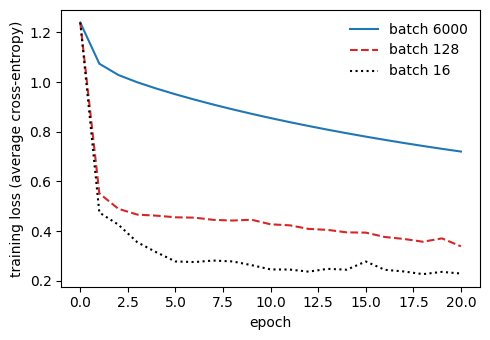

In [22]:
rng = np.random.default_rng(12)
n_obs, n_in = 6000, 10
Xs = rng.normal(size=(n_obs, n_in))
T1 = rng.normal(size=(n_in, 8))
T2 = 1.5 * rng.normal(size=(8, 3))
Ys = (np.tanh(Xs @ T1) @ T2 + 0.5 * rng.gumbel(size=(n_obs, 3))).argmax(axis=1)
Xj, Yj = jnp.array(Xs), jnp.array(Ys)
print("class counts:", np.bincount(Ys))

def init_net(key, hidden=32):
    ka, kb = random.split(key)
    return [0.3 * random.normal(ka, (n_in, hidden)), jnp.zeros(hidden),
            0.3 * random.normal(kb, (hidden, 3)), jnp.zeros(3)]

def loss_net(p, x, y):
    z = jax.nn.sigmoid(x @ p[0] + p[1])
    s = z @ p[2] + p[3]
    return jnp.mean(jax.nn.logsumexp(s, axis=1) - s[jnp.arange(len(y)), y])

@jit
def sgd_step(p, x, y, lr):
    g = grad(loss_net)(p, x, y)
    return [a - lr * b for a, b in zip(p, g)]

def train_minibatch(m, lr=0.5, epochs=20, seed=0):
    order = np.random.default_rng(seed)
    p = init_net(random.PRNGKey(0))
    curve, t0 = [float(loss_net(p, Xj, Yj))], time.time()
    for ep in range(epochs):
        idx = order.permutation(n_obs)
        for i in range(0, n_obs, m):
            j = idx[i:i + m]
            p = sgd_step(p, Xj[j], Yj[j], lr)
        curve.append(float(loss_net(p, Xj, Yj)))
    return curve, (time.time() - t0) / epochs

fig, ax = plt.subplots(figsize=(5, 3.5))
results = {}
print(f"starting loss (all three runs): {float(loss_net(init_net(random.PRNGKey(0)), Xj, Yj)):.3f}")
for m, color, style in ((n_obs, "C0", "-"), (128, "C3", "--"), (16, "k", ":")):
    curve, secs = results[m] = train_minibatch(m)
    ax.plot(curve, color=color, ls=style, label=f"batch {m}")
    print(f"batch {m:5d}: {-(-n_obs // m):5d} steps per epoch, loss after 20 epochs {curve[-1]:.3f}, {secs:.3f} s per epoch")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss (average cross-entropy)")
ax.legend(frameon=False)
fig.tight_layout()


- All three runs start at loss 1.239.
- After 20 epochs: full batch 0.720, batch 128 0.339, batch 16 0.230.
- Steps per epoch: 1 (full batch), 47 (batch 128), 375 (batch 16). Smaller batches learn more per epoch.
- 6000/128 gives 47 steps, and the last batch has 112 examples.
- Price: many small steps in a Python loop take more seconds per epoch (see the printed times). On a GPU a tiny batch also leaves the chip mostly idle.
- Trade-off: steps that are cheap but noisy against steps that are expensive but accurate.

### The minibatch gradient is noisy but unbiased

Fix the weights. Compute the full-data gradient once. Draw 1,000 random minibatches and compute the gradient of each. Follow one entry of the gradient (the first output weight).


In [23]:
p0 = init_net(random.PRNGKey(0))
g_full = float(grad(loss_net)(p0, Xj, Yj)[2][0, 0])
gdraw = grad(loss_net)
sd_by_m = {}
print(f"full-data gradient entry: {g_full:.4f}")
for m in (16, 128):
    r = np.random.default_rng(5)
    vals = np.array([float(gdraw(p0, Xj[j], Yj[j])[2][0, 0])
                     for j in (r.choice(n_obs, m, replace=False) for _ in range(1000))])
    sd_by_m[m] = vals.std()
    print(f"batch {m:3d}: mean of 1000 minibatch gradients {vals.mean():.4f}, standard deviation {vals.std():.4f}")


full-data gradient entry: -0.0579


batch  16: mean of 1000 minibatch gradients -0.0604, standard deviation 0.0673


batch 128: mean of 1000 minibatch gradients -0.0586, standard deviation 0.0248


- Full gradient entry: -0.0579. The average of 1,000 minibatch gradients is close to it for both sizes: unbiased, because a random batch is a fair sample of the data.
- Noise: standard deviation 0.0673 for batch 16 and 0.0248 for batch 128, a ratio of 2.72.
- Rule: the noise falls like $1/\sqrt{m}$. The ratio is close to $\sqrt{128/16} = 2.83$.

### Memory in bytes

- Memory of a tensor: number of entries times bytes per entry.
- Backpropagation keeps the activations of every layer from the forward pass. A batch of $m$ examples through a layer of $u$ units stores $m \times u$ numbers. Memory grows with the batch size $m$.
- Float32: 4 bytes per number. 1 megabyte (MB) is $10^6$ bytes.
- The totals below are a subtotal: only the activations. Weights, their gradients, other intermediates and library workspace come on top.


In [24]:
def nbytes(shape, bytes_per_entry):
    return int(np.prod(shape)) * bytes_per_entry

# a batch of 128 images of 28 x 28 pixels, float32
batch_bytes = nbytes((128, 28, 28), 4)
print(f"128 images of 28 x 28 in float32: {batch_bytes:,} bytes = {batch_bytes / 1e6:.3f} MB")

# activations kept for the backward pass in a 784-512-512-10 network, batch of 128
layers = {"input": 784, "hidden 1": 512, "hidden 2": 512, "scores": 10}
total = 0
for name, width in layers.items():
    b = nbytes((128, width), 4)
    total += b
    print(f"  {name:9s} (128, {width:3d}): {b:>9,} bytes")
print(f"subtotal of activations kept, batch 128: {total:,} bytes = {total / 1e6:.2f} MB (weights, gradients and workspace not counted)")
print(f"same network, batch 128 in float16: {total // 2:,} bytes")
weights_70b = 70e9 * 2
print(f"a model with 70 billion weights in float16: {weights_70b / 1e9:.0f} GB (more than one 80 GB GPU holds, before any activations or gradients)")
print(f"same network, batch 1,024 in float32: {sum(nbytes((1024, w), 4) for w in (784, 512, 512, 10)) / 1e6:.2f} MB")


128 images of 28 x 28 in float32: 401,408 bytes = 0.401 MB
  input     (128, 784):   401,408 bytes
  hidden 1  (128, 512):   262,144 bytes
  hidden 2  (128, 512):   262,144 bytes
  scores    (128,  10):     5,120 bytes
subtotal of activations kept, batch 128: 930,816 bytes = 0.93 MB (weights, gradients and workspace not counted)
same network, batch 128 in float16: 465,408 bytes
a model with 70 billion weights in float16: 140 GB (more than one 80 GB GPU holds, before any activations or gradients)
same network, batch 1,024 in float32: 7.45 MB


- 128 images of $28 \times 28$ pixels: $128 \times 784 \times 4$ = 401,408 bytes, about 0.40 MB.
- Stored activations of the 784-512-512-10 network, batch 128: 0.93 MB. Batch 1,024 is 8 times more.
- Memory grows in proportion to $m$ and to the width and depth of the network.
- The weights of a 70-billion-weight model in float16 take 140 GB, more than one 80 GB GPU holds. That is the other reason to use many GPUs.

### Data parallelism as map-reduce

- Data parallelism: every GPU holds a full copy of the model. Each minibatch is cut into shards, one per GPU.
- Map: each GPU computes the gradient on its own shard.
- Reduce: average the gradients. On real hardware this is an all-reduce: every GPU ends up with the same average.
- Every copy takes the same step, so the copies stay identical.
- Identity: the average of the shard gradients equals the full-batch gradient. It needs equal shard sizes, the same weights on every shard, and a loss that is an average of per-example terms. Batch normalization mixes the examples of a batch and needs more care.

Simulated on one CPU: the "GPUs" are 4 slices of a batch of 128.


In [25]:
idx_batch = np.arange(128)                       # one minibatch of 128 examples
xb, yb = Xj[idx_batch], Yj[idx_batch]
g_full_batch = grad(loss_net)(p0, xb, yb)

shard_ids = np.array_split(idx_batch, 4)         # 4 shards of 32
shard_grads = [grad(loss_net)(p0, Xj[s], Yj[s]) for s in shard_ids]            # map
g_avg = [sum(g[i] for g in shard_grads) / 4 for i in range(4)]                  # reduce
diffs = [float(jnp.abs(a - b).max()) for a, b in zip(g_avg, g_full_batch)]
print("shard sizes:", [len(s) for s in shard_ids])
print("largest difference per weight array:", [f"{d:.1e}" for d in diffs])
print("largest gradient entry:", f"{max(float(jnp.abs(a).max()) for a in g_full_batch):.3f}")

# Training for 50 steps: one copy on batch 128, against 4 shards with averaged gradients.
pa = init_net(random.PRNGKey(0))
pb = init_net(random.PRNGKey(0))
for t in range(50):
    ids = np.random.default_rng(t).choice(n_obs, 128, replace=False)
    pa = sgd_step(pa, Xj[ids], Yj[ids], 0.5)
    sg = [grad(loss_net)(pb, Xj[s], Yj[s]) for s in np.array_split(ids, 4)]
    pb = [w - 0.5 * sum(g[i] for g in sg) / 4 for i, w in enumerate(pb)]
max_wdiff = max(float(jnp.abs(a - b).max()) for a, b in zip(pa, pb))
print("largest difference between the two sets of weights after 50 steps:", f"{max_wdiff:.1e}")
n_params = sum(int(np.prod(a.shape)) for a in pa)
print(f"parameters: {n_params}, gradient message per step: {n_params * 4:,} bytes")
print(f"for a 1-billion-weight model in float32: {1e9 * 4 / 1e9:.0f} GB per step per GPU")


shard sizes: [32, 32, 32, 32]
largest difference per weight array: ['1.1e-08', '0.0e+00', '5.2e-08', '0.0e+00']
largest gradient entry: 0.219


largest difference between the two sets of weights after 50 steps: 3.0e-07
parameters: 451, gradient message per step: 1,804 bytes
for a 1-billion-weight model in float32: 4 GB per step per GPU


- Largest difference between the averaged shard gradient and the full-batch gradient: 5.2e-08. Gradient entries are about 0.22. The difference is float32 rounding (sums in a different order). In exact arithmetic they are equal.
- After 50 steps the two networks differ by at most 3.0e-07. Data-parallel training takes the same steps as one big batch.
- Communication cost: every step each GPU exchanges its gradient. This network has 451 weights, so the message is 1,804 bytes. A billion weights give 4 GB per step. The network between GPUs becomes the bottleneck.
- Bigger effective batch: 4 shards of 32 make a step of 128 examples. Less noise per step, but the best learning rate often changes.
- Unequal shards: weight each shard gradient by its size and divide by the total number of examples.
- Model parallelism: a model too big for one GPU is split across GPUs (each holds some layers). Data parallelism is not enough there.

**Recorded on two GPUs.** Two NVIDIA A100 (80 GB) in one server on GMU's Hopper cluster, 22 October 2026. Each GPU computed the gradient on its own shard and an all-reduce averaged the two. Largest difference from the full-batch gradient: 2.2e-08, float32 rounding. The all-reduce alone was then timed (float32, 4 bytes per number).

| Parameters | Gradient size | Time per all-reduce | Rate |
|---|---|---|---|
| 1 million | 4 MB | 0.099 ms | 40 GB/s |
| 10 million | 40 MB | 0.66 ms | 59 GB/s |
| 100 million | 400 MB | 5.86 ms | 67 GB/s |
| 1 billion | 4,000 MB | 54 ms | 73 GB/s |

- One $8{,}192 \times 8{,}192$ bfloat16 product on the same GPU: 3.81 ms.
- Averaging the gradient of a 100-million-parameter model (5.86 ms) costs about 1.5 such products, at every step.
- Communication grows with the size of the model. Large runs send gradients while the next computation is already running.

### Watts and megawatts

- Energy: power times time. Power is in watts (W): one joule per second. A GPU at 700 W for one hour uses $700 \times 3600$ joules = 0.7 kilowatt-hours (kWh).
- FLOP per joule: floating-point operations done per joule. Peak speed (FLOP per second) divided by power (watts).
- Energy of a run: FLOP of the run divided by FLOP per joule.
- 1 MW (megawatt) = $10^6$ W. 1 MWh (megawatt-hour) = 1,000 kWh = $3.6 \times 10^9$ joules.

**Recorded power.** One NVIDIA A100 (80 GB) on GMU's Hopper cluster, 22 October 2026. Power read every 0.1 s with `nvidia-smi` while the GPU repeated $8{,}192 \times 8{,}192$ matrix products for 3 seconds. Power limit of this GPU: 500 W.

| Work | Power (W) | TFLOP/s | TFLOP per joule | Energy for one product |
|---|---|---|---|---|
| Idle | 65 | | | |
| float32 | 317 | 19 | 0.06 | 18.3 J |
| TF32 | 487 | 140 | 0.29 | 3.8 J |
| bfloat16 | 485 | 289 | 0.60 | 1.8 J |

- TFLOP per joule: TFLOP/s divided by watts.
- In bfloat16 the GPU draws more power than in float32 (485 W against 317 W) but finishes the same product with 10 times less energy (1.8 J against 18.3 J). Energy and speed are two reasons AI training uses bfloat16.

**From one GPU to a data center.** An assumption-based estimate, not a measurement. The assumptions are in the code:

- 700 W per GPU, drawn all the time. Newer GPUs than the A100 above.
- Peak speed $10^{15}$ FLOP per second per GPU (16-bit arithmetic). Real training uses 40% of it.
- 100,000 GPUs.
- Cooling, networking and the building add a factor of 1.2 to 1.5 on top of the chips.
- A training run of $10^{24}$ FLOP (an assumed size for a very large model).
- A household uses about 10.8 MWh per year.


In [26]:
gpu_watts = 700
n_gpus = 100_000
peak_flops = 1e15
utilization = 0.40
overhead = (1.2, 1.5)
run_flop = 1e24
household_mwh_per_year = 10.8

chips_mw = gpu_watts * n_gpus / 1e6
building_mw = (chips_mw * overhead[0], chips_mw * overhead[1])
flop_per_joule = peak_flops / gpu_watts
real_flop_per_joule = flop_per_joule * utilization
run_joules = run_flop / real_flop_per_joule
run_mwh = run_joules / 3.6e9                 # 1 MWh = 3.6e9 joules
run_hours = run_flop / (n_gpus * peak_flops * utilization) / 3600
day_mwh = chips_mw * 24
print(f"chips alone: {chips_mw:.0f} MW; with the building: {building_mw[0]:.0f} to {building_mw[1]:.0f} MW")
print(f"one day of the chips: {day_mwh:,.0f} MWh = {day_mwh / household_mwh_per_year:.0f} household-years of electricity")
print(f"peak FLOP per joule: {flop_per_joule:.2e}; at 40% use: {real_flop_per_joule:.2e}")
print(f"a 1e24 FLOP run: {run_mwh:,.0f} MWh for the chips, in {run_hours:.1f} hours on 100,000 GPUs")


chips alone: 70 MW; with the building: 84 to 105 MW
one day of the chips: 1,680 MWh = 156 household-years of electricity
peak FLOP per joule: 1.43e+12; at 40% use: 5.71e+11
a 1e24 FLOP run: 486 MWh for the chips, in 6.9 hours on 100,000 GPUs


- 100,000 GPUs at 700 W draw 70 MW for the chips. With the building: 84 to 105 MW.
- One day of the chips: 1,680 MWh, the energy of 156 households in one year.
- The $10^{24}$ FLOP run needs about 486 MWh at the chips and takes about 6.9 hours on the whole cluster.
- Change any assumption and the answer scales in proportion.
